# Stage A: results viewer (read-only)
Reads the finished runs from `features_hifigan\stageA\` and shows them in detail: which model is which, every participant, paired comparisons.
It never trains anything. Re-run the cells at any time while training is going on; only finished runs appear.

In [1]:
import os, sys
ROOT = r"C:\seeg_v2"; os.chdir(ROOT); sys.path.insert(0, ROOT)
os.environ["SEEG_OUT_DIR"] = r"C:\seeg_v2\features_hifigan"
import importlib, pandas as pd
import stageA_report as R; importlib.reload(R)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
df = R.load_runs()
print(len(df), "participant-level rows from", df.groupby(["model","seed"]).ngroups, "finished runs")

90 participant-level rows from 9 finished runs


## 1) Progress: finished runs and the end of each log

In [2]:
R.status()

finished runs (9):
   baseline_lr0.0001_seed123
   baseline_lr0.0001_seed42
   baseline_lr0.0001_seed456
   baseline_null_lr0.0001_seed42
   hybrid_lr0.0001_seed123
   hybrid_lr0.0001_seed42
   hybrid_lr0.0001_seed456
   hybrid_null_lr0.0001_seed42
   linear_seedNA

--- log_baseline.txt (last 4 lines)
    [baseline lr=0.0001 seed=456] epoch 14/60: train MSE 0.1757 | val MSE 0.5948 | 53s
    [baseline lr=0.0001 seed=456] epoch 15/60: train MSE 0.1694 | val MSE 0.5665 | 54s
    [baseline lr=0.0001 seed=456] epoch 16/60: train MSE 0.1662 | val MSE 0.5693 | 56s
  baseline_lr0.0001_seed456: mean test PCC 0.703 | template 0.744 | residual +0.369

--- log_baseline_null.txt (last 4 lines)
    [baseline_null lr=0.0001 seed=42] epoch 9/60: train MSE 0.4551 | val MSE 1.3229 | 55s
  baseline_null: lr 0.0001 -> best validation MSE 1.0246
  baseline_null: chosen lr = 0.0001
  baseline_null_lr0.0001_seed42: mean test PCC 0.044 | template 0.744 | residual -0.007

--- log_hybrid.txt (last 4 lines)
    

## 2) All models side by side (mean over the participants, then mean ± sd over seeds)
`PCC − template` is what the model adds beyond the no-neural-input template. `in speech` = only frames where speech is present.

In [3]:
R.model_table(df)

,seeds,lr,PCC,template PCC,PCC − template,PCC in speech,template in speech,in speech − template,residual PCC
model,,,,,,,,,
"Linear (Verwoert-style, pooled)",1,NaN,+0.472,+0.744,-0.272,+0.161,+0.236,-0.075,+0.132
Baseline CNN-BiLSTM,3,0.0001,+0.705 ± 0.004,+0.744 ± 0.000,-0.039 ± 0.004,+0.219 ± 0.010,+0.236 ± 0.000,-0.017 ± 0.010,+0.371 ± 0.001
Hybrid (MR-ResBlocks),3,0.0001,+0.696 ± 0.004,+0.744 ± 0.000,-0.048 ± 0.004,+0.232 ± 0.006,+0.236 ± 0.000,-0.004 ± 0.006,+0.369 ± 0.006
"Baseline, noise input",1,0.0001,+0.044,+0.744,-0.701,+0.005,+0.236,-0.231,-0.007
"Hybrid, noise input",1,0.0001,+0.170,+0.744,-0.575,+0.041,+0.236,-0.195,-0.009


## 3) PCC for EACH participant, every model next to the template

In [4]:
R.subject_table(df, "pcc")

,"Linear (Verwoert-style, pooled)",Baseline CNN-BiLSTM,Hybrid (MR-ResBlocks),"Baseline, noise input","Hybrid, noise input",Template (no neural input)
subject,,,,,,
sub-01,0.059,0.569,0.558,0.088,0.174,0.664
sub-02,0.495,0.652,0.600,-0.024,0.201,0.733
sub-03,0.599,0.741,0.774,0.071,0.204,0.816
sub-04,0.493,0.747,0.718,0.076,0.241,0.805
sub-05,0.406,0.614,0.589,0.067,0.173,0.741
sub-06,0.708,0.842,0.847,0.078,0.212,0.784
sub-07,0.429,0.723,0.705,-0.026,0.258,0.684
sub-08,0.581,0.710,0.735,0.092,0.171,0.815
sub-09,0.412,0.795,0.777,0.048,0.149,0.792


In [10]:
R.subject_table(df, "pcc_in_speech")

,"Linear (Verwoert-style, pooled)",Baseline CNN-BiLSTM,Hybrid (MR-ResBlocks),"Baseline, noise input","Hybrid, noise input",Template (no neural input)
subject,,,,,,
sub-01,-0.007,0.164,0.194,0.035,0.036,0.190
sub-02,0.080,0.102,0.094,-0.001,0.084,0.155
sub-03,0.196,0.246,0.296,0.013,0.006,0.282
sub-04,0.140,0.216,0.189,0.017,0.063,0.306
sub-05,0.145,0.235,0.165,0.000,0.058,0.247
sub-06,0.230,0.388,0.418,-0.001,0.033,0.252
sub-07,0.171,0.287,0.282,-0.008,0.092,0.288
sub-08,0.157,0.142,0.211,0.015,-0.007,0.253
sub-09,0.226,0.213,0.217,-0.001,0.035,0.235


## 4) Hybrid vs Baseline (and the others): paired by participant, exact Wilcoxon (n = number of participants)

In [5]:
R.paired_table(df, [("hybrid","baseline"), ("hybrid","linear"), ("hybrid","neuroincept"), ("hybrid","convedsr"),
                    ("baseline","neuroincept"), ("baseline","convedsr"), ("hybrid","hybrid_null")])

,comparison,metric,n,mean_diff,a_better_in,p_exact_two_sided
0,Hybrid (MR-ResBlocks) minus Baseline CNN-BiLSTM,pcc,10,-0.0095,3/10,0.3223
1,Hybrid (MR-ResBlocks) minus Baseline CNN-BiLSTM,pcc_in_speech,10,0.0128,6/10,0.4316
2,Hybrid (MR-ResBlocks) minus Baseline CNN-BiLSTM,residual_pcc,10,-0.0017,6/10,0.9219
3,Hybrid (MR-ResBlocks) minus Linear (Verwoert...,pcc,10,0.2242,10/10,0.0020
4,Hybrid (MR-ResBlocks) minus Linear (Verwoert...,pcc_in_speech,10,0.0710,8/10,0.0137
5,Hybrid (MR-ResBlocks) minus Linear (Verwoert...,residual_pcc,10,0.2365,10/10,0.0020
6,"Hybrid (MR-ResBlocks) minus Hybrid, noise input",pcc,10,0.5265,10/10,0.0020
7,"Hybrid (MR-ResBlocks) minus Hybrid, noise input",pcc_in_speech,10,0.1913,10/10,0.0020
8,"Hybrid (MR-ResBlocks) minus Hybrid, noise input",residual_pcc,10,0.3779,10/10,0.0020


In [ ]:
R.paired(df, "hybrid", "baseline", "pcc")[1]    # per-participant differences hybrid − baseline

## 5) Figures

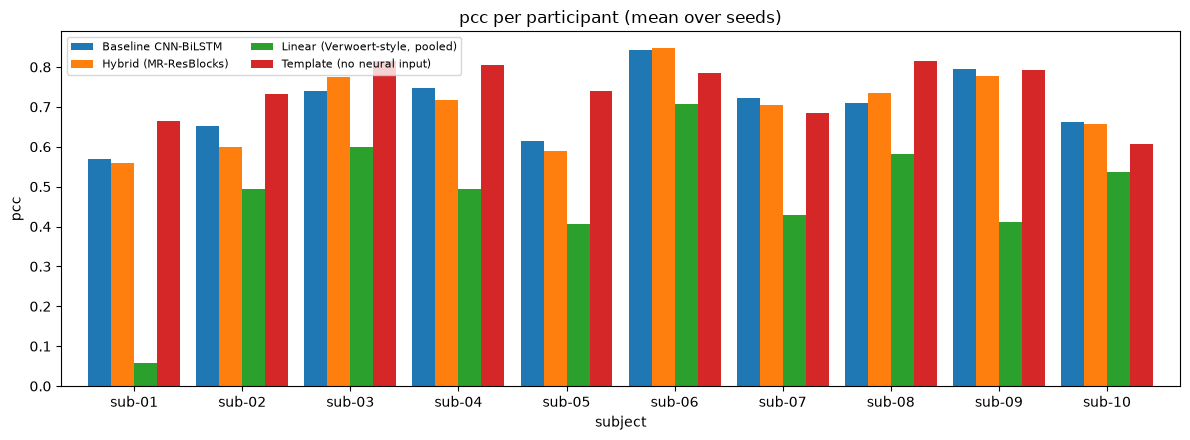

In [6]:
R.plot_subjects(df, "pcc")

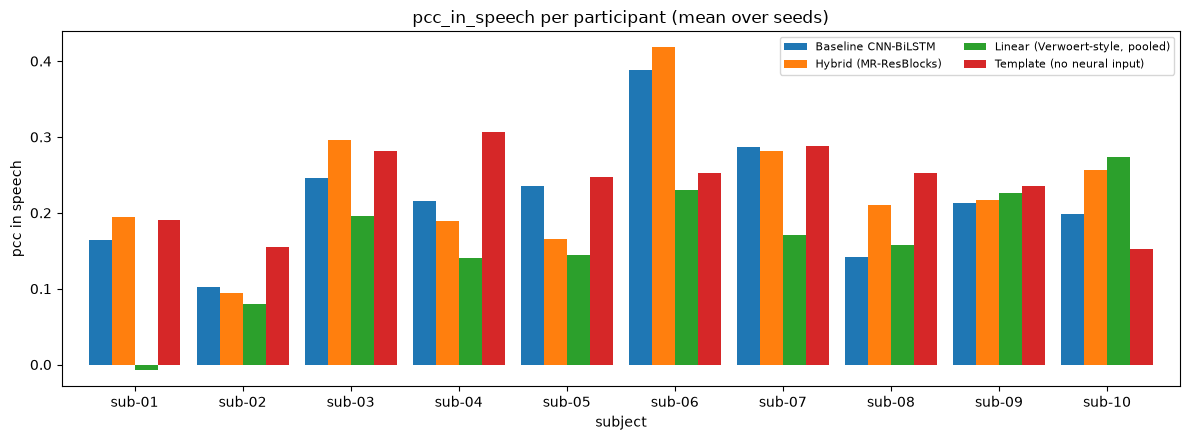

In [7]:
R.plot_subjects(df, "pcc_in_speech")

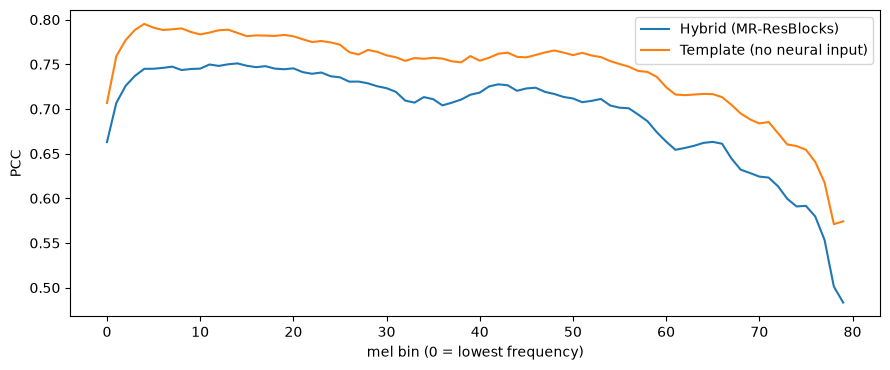

In [8]:
R.per_bin_pcc(model="hybrid")

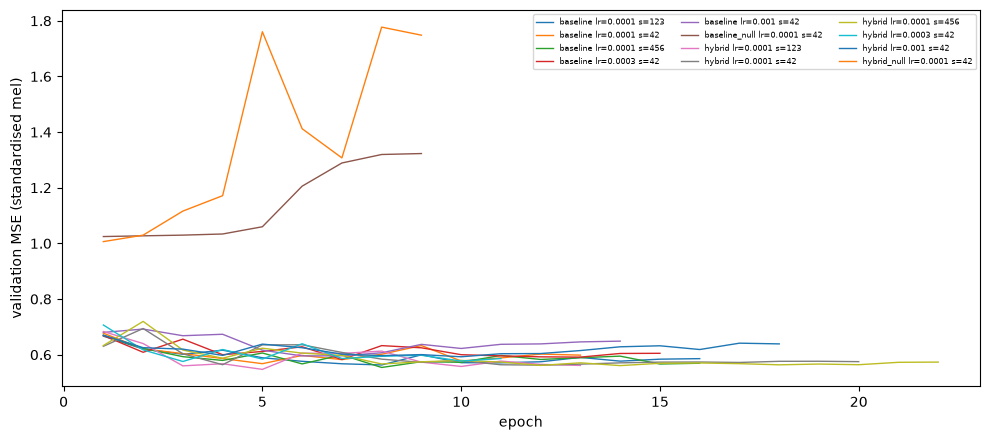

12

In [9]:
R.learning_curves()